# 01 · Exploratory Data Analysis: Global Fishing Effort 2024
**Machine Learning and Data Analytics, Coursework 1 · Student ID: 18503**

**Data:** Global Fishing Watch, *Global AIS-based Apparent Fishing Effort Dataset v3.0* (2024), CC BY-NC 4.0.
Working sample built by `src/make_sample.py` (stratified by gear type and month, joined to a flag × gear vessel summary).

**Questions this notebook answers**
1. Is the data clean enough to model? (missing values, duplicates, impossible values)
2. What does the target (`fishing_hours`) look like, and how should it be transformed?
3. How do fishing effort, gear type, flag, season and location relate?
4. Which features are redundant or leak the target?
5. What preprocessing decisions follow (carried into notebook 02)?

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Work from the repository root whether the notebook is run from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "fishing_sample.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Validated palette (single hue for magnitude, blue<->red for correlation sign)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 2. Load the data

In [2]:
df = pd.read_parquet(DATA)
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   Memory: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
df.head()

Rows: 319,162   Columns: 16   Memory: 49.0 MB


,date,year,month,cell_ll_lat,cell_ll_lon,flag,geartype,hours,fishing_hours,mmsi_present,n_vessels,mean_length_m,mean_engine_kw,mean_tonnage_gt,share_self_reported,mean_class_score
0,2024-09-01,2024,9,54.1,-131.1,CAN,seiners,1.1750,0.0000,1,1,16.965000,164.598000,15.000000,1.000000,0.506000
1,2024-12-01,2024,12,-6.2,60.3,LKA,drifting_longlines,19.8752,0.0000,3,1880,20.771341,361.513994,72.195699,0.973404,0.850347
2,2024-03-01,2024,3,35.3,123.7,GRC,fishing,13.3066,13.3066,1,16,18.839750,149.965688,53.888937,1.000000,0.796867
3,2024-10-01,2024,10,52.8,2.7,GBR,seiners,1.7333,1.0044,1,5,27.074600,612.213400,322.900000,0.800000,0.606600
4,2024-10-01,2024,10,59.1,4.9,NOR,seiners,0.5336,0.0000,1,58,23.698276,577.564034,212.446845,0.948276,0.661138


In [3]:
df.dtypes.to_frame('dtype').join(df.nunique().rename('n_unique'))

,dtype,n_unique
date,str,12
year,int64,1
month,int64,12
cell_ll_lat,float64,1555
cell_ll_lon,float64,3600
flag,str,274
geartype,str,16
hours,float64,84727
fishing_hours,float64,55465
mmsi_present,int64,246


## 3. Data quality
Checks: missing values, duplicates, impossible values, coordinate ranges, flag problems.

In [4]:
miss = df.isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(df) * 100).round(2)
print(miss[miss["missing"] > 0] if (miss["missing"] > 0).any() else "No missing values")

checks = {
    "duplicate rows": int(df.duplicated().sum()),
    "fishing_hours > hours": int((df["fishing_hours"] > df["hours"] + 1e-9).sum()),
    "negative hours": int((df[["hours", "fishing_hours"]] < 0).any(axis=1).sum()),
    "latitude outside [-90, 90]": int((~df["cell_ll_lat"].between(-90, 90)).sum()),
    "longitude outside [-180, 180]": int((~df["cell_ll_lon"].between(-180, 180)).sum()),
    "year != 2024": int((df["year"] != 2024).sum()),
    "flag UNKNOWN*": int(df["flag"].astype(str).str.startswith("UNKNOWN").sum()),
}
pd.Series(checks, name="rows").to_frame()

                  missing   pct
mean_class_score     1220  0.38


,rows
duplicate rows,0
fishing_hours > hours,0
negative hours,0
"latitude outside [-90, 90]",0
"longitude outside [-180, 180]",0
year != 2024,0
flag UNKNOWN*,16523


In [5]:
# Does `date` agree with `month`?
bad_month = (pd.to_datetime(df["date"]).dt.month != df["month"]).sum()
print("Rows where date month != month column:", bad_month)
print("Distinct flags:", df["flag"].nunique(), "| distinct gear types:", df["geartype"].nunique())

Rows where date month != month column: 0
Distinct flags: 274 | distinct gear types: 16


## 4. Summary statistics

In [6]:
num_cols = ["hours", "fishing_hours", "mmsi_present", "n_vessels", "mean_length_m",
            "mean_engine_kw", "mean_tonnage_gt", "share_self_reported", "mean_class_score"]
df[num_cols].describe(percentiles=[.25, .5, .75, .95, .99]).T.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
hours,319162.0,26.04,437.70,0.0,0.50,1.13,5.57,66.36,474.27,188783.36
fishing_hours,319162.0,6.76,54.34,0.0,0.00,0.00,0.96,25.00,123.78,12479.95
mmsi_present,319162.0,2.64,7.82,1.0,1.00,1.00,2.00,8.00,25.00,604.00
n_vessels,319162.0,443.02,1683.83,1.0,18.00,65.00,239.00,1098.00,10334.00,19322.00
mean_length_m,319162.0,31.20,14.90,8.1,20.55,27.07,36.86,61.49,74.40,87.26
mean_engine_kw,319162.0,702.77,649.64,35.0,267.99,499.38,852.39,2221.51,2965.00,4043.05
mean_tonnage_gt,319162.0,346.03,533.63,2.2,78.81,202.42,408.26,1160.89,1744.86,78440.17
share_self_reported,319162.0,0.85,0.15,0.0,0.80,0.88,0.94,1.00,1.00,1.00
mean_class_score,317942.0,0.75,0.10,0.5,0.69,0.75,0.82,0.93,0.96,1.00


In [7]:
# Skewness: values far above 1 mean a log transform will help
df[num_cols].skew().round(2).sort_values(ascending=False).to_frame("skewness")

,skewness
hours,282.93
fishing_hours,65.62
mean_tonnage_gt,59.99
mmsi_present,23.73
n_vessels,8.19
mean_engine_kw,2.02
mean_length_m,1.22
mean_class_score,0.19
share_self_reported,-2.60


## 5. Target: `fishing_hours`
Each row is one 0.1° cell × month × flag × gear. Many cells record vessel presence but no apparent fishing, so the target is expected to be **zero-inflated and heavily right-skewed**. That motivates a two-part model: (a) does any fishing occur, (b) how much, given that it does.

In [8]:
df["any_fishing"] = (df["fishing_hours"] > 0).astype(int)
df["log_fishing_hours"] = np.log1p(df["fishing_hours"])
df["fishing_share"] = np.where(df["hours"] > 0, df["fishing_hours"] / df["hours"], np.nan)

zero_share = 1 - df["any_fishing"].mean()
print(f"Rows with zero fishing hours: {zero_share:.1%}")
print(f"Rows with fishing: {1-zero_share:.1%}")
pos = df[df["any_fishing"] == 1]
print(f"Among fishing rows: median {pos['fishing_hours'].median():.2f} h, "
      f"mean {pos['fishing_hours'].mean():.2f} h, 99th pct {pos['fishing_hours'].quantile(.99):.1f} h")

Rows with zero fishing hours: 68.2%
Rows with fishing: 31.8%
Among fishing rows: median 4.00 h, mean 21.30 h, 99th pct 287.6 h


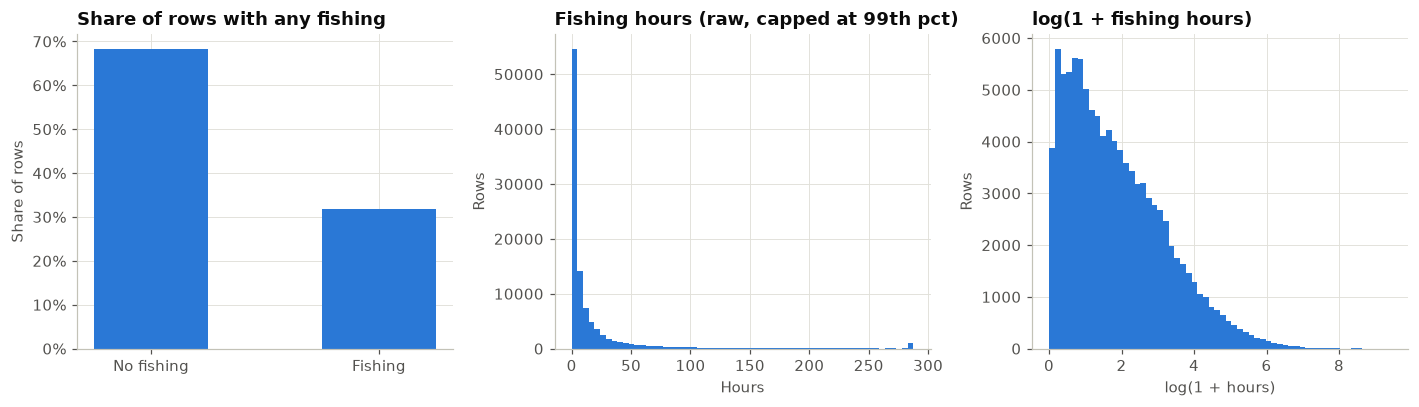

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].bar(["No fishing", "Fishing"], [zero_share, 1 - zero_share], color=BLUE, width=0.5)
ax[0].set_title("Share of rows with any fishing"); ax[0].set_ylabel("Share of rows")
ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))

ax[1].hist(pos["fishing_hours"].clip(upper=pos["fishing_hours"].quantile(.99)), bins=60, color=BLUE)
ax[1].set_title("Fishing hours (raw, capped at 99th pct)"); ax[1].set_xlabel("Hours"); ax[1].set_ylabel("Rows")

ax[2].hist(pos["log_fishing_hours"], bins=60, color=BLUE)
ax[2].set_title("log(1 + fishing hours)"); ax[2].set_xlabel("log(1 + hours)"); ax[2].set_ylabel("Rows")
fig.tight_layout(); save(fig, "01_target_distribution")

In [10]:
from scipy import stats
print(f"Skewness among fishing rows - raw: {stats.skew(pos['fishing_hours']):.2f}, "
      f"log1p: {stats.skew(pos['log_fishing_hours']):.2f}")

Skewness among fishing rows - raw: 38.44, log1p: 0.86


## 6. Gear type

> **Caution:** the sample is stratified, so each gear type has about 20,000 rows. Row counts per gear are therefore **not** real-world prevalence. Compare *rates and averages within gear type*, never counts.

In [11]:
g = (df.groupby("geartype")
       .agg(rows=("any_fishing", "size"), share_fishing=("any_fishing", "mean"),
            median_hours_if_fishing=("fishing_hours", lambda s: s[s > 0].median()),
            mean_hours=("hours", "mean"))
       .sort_values("share_fishing", ascending=False))
g.round(3)

,rows,share_fishing,median_hours_if_fishing,mean_hours
geartype,,,,
set_gillnets,20004,0.537,7.943,66.486
drifting_longlines,20004,0.493,2.229,4.705
dredge_fishing,20004,0.459,7.931,70.098
fixed_gear,20004,0.417,6.445,34.976
trawlers,20004,0.412,5.551,48.742
fishing,20004,0.392,5.508,45.419
other_seines,19925,0.374,2.824,18.730
set_longlines,20004,0.334,4.614,14.534
pole_and_line,20004,0.293,3.088,14.066


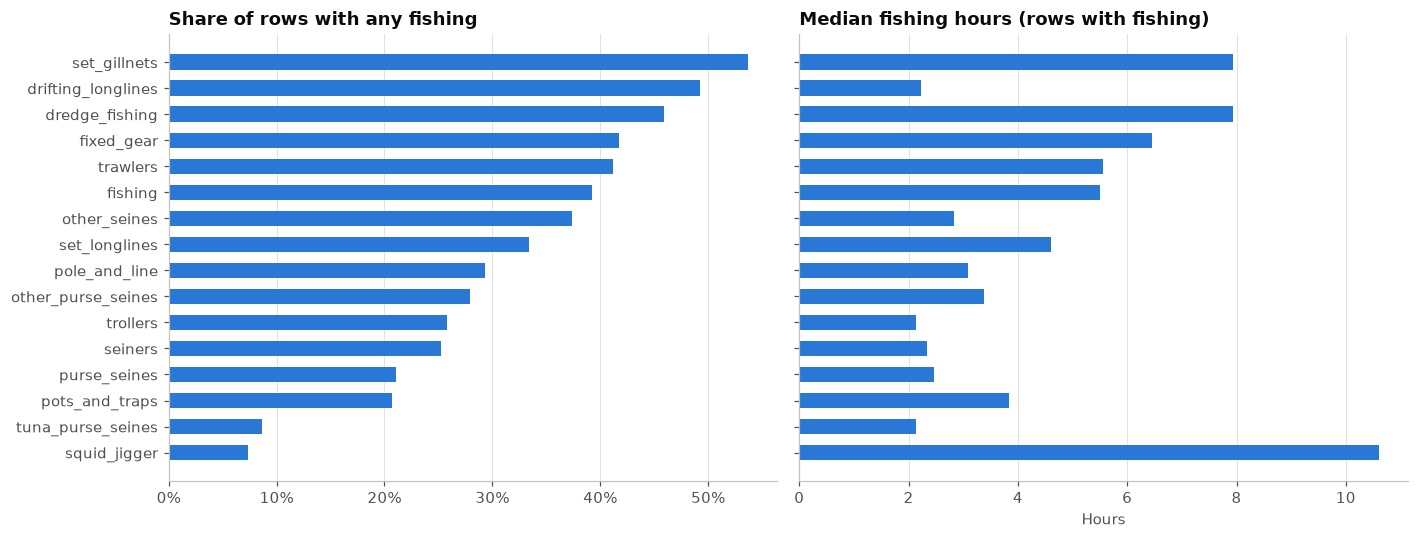

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
order = g.sort_values("share_fishing").index
ax[0].barh(order, g.loc[order, "share_fishing"], color=BLUE, height=0.6)
ax[0].set_title("Share of rows with any fishing"); ax[0].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax[1].barh(order, g.loc[order, "median_hours_if_fishing"], color=BLUE, height=0.6)
ax[1].set_title("Median fishing hours (rows with fishing)"); ax[1].set_xlabel("Hours")
ax[0].grid(axis="y", visible=False); ax[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "02_gear_profile")

C:\Users\Shoafzal\AppData\Local\Temp\ipykernel_67020\3991326173.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, tick_labels=order, patch_artist=True, showfliers=False,


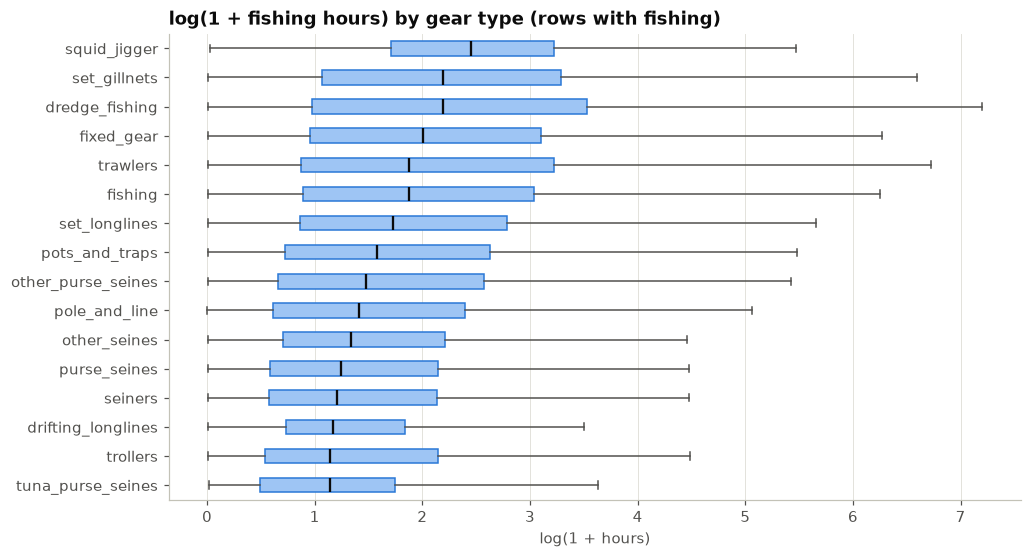

In [13]:
# Distribution of fishing hours by gear (log scale to handle the skew)
order = df[df.any_fishing == 1].groupby("geartype")["log_fishing_hours"].median().sort_values().index
data = [df.loc[(df.geartype == gname) & (df.any_fishing == 1), "log_fishing_hours"] for gname in order]
fig, ax = plt.subplots(figsize=(10, 5.5))
bp = ax.boxplot(data, vert=False, tick_labels=order, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for b in bp["boxes"]:
    b.set(facecolor="#9ec5f4", edgecolor=BLUE)
ax.set_title("log(1 + fishing hours) by gear type (rows with fishing)"); ax.set_xlabel("log(1 + hours)")
ax.grid(axis="y", visible=False); save(fig, "03_hours_by_gear")

## 7. Season

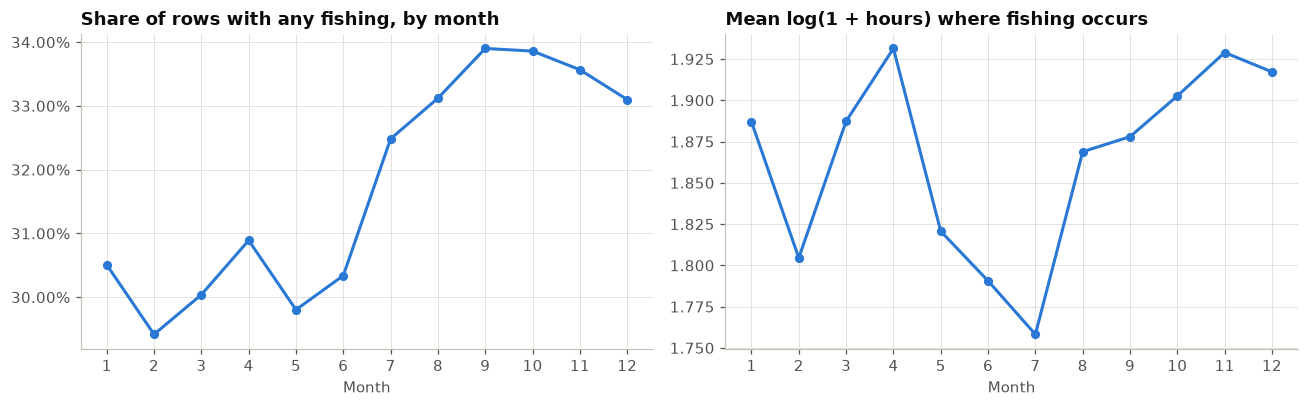

In [14]:
m = df.groupby("month").agg(share_fishing=("any_fishing", "mean"),
                            mean_log_hours=("log_fishing_hours", lambda s: s[s > 0].mean()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(m.index, m["share_fishing"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax[0].set_title("Share of rows with any fishing, by month"); ax[0].set_xlabel("Month")
ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax[1].plot(m.index, m["mean_log_hours"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax[1].set_title("Mean log(1 + hours) where fishing occurs"); ax[1].set_xlabel("Month")
for a in ax: a.set_xticks(range(1, 13))
fig.tight_layout(); save(fig, "04_monthly_pattern")

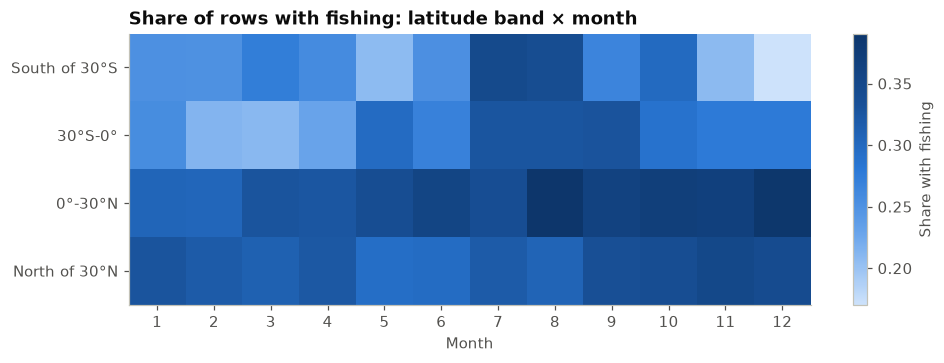

In [15]:
# Seasonality differs by hemisphere, so look at it by latitude band
df["lat_band"] = pd.cut(df["cell_ll_lat"], [-90, -30, 0, 30, 90],
                        labels=["South of 30°S", "30°S-0°", "0°-30°N", "North of 30°N"])
pivot = df.pivot_table(index="lat_band", columns="month", values="any_fishing", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(pivot.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_yticks(range(len(pivot))); ax.set_yticklabels(pivot.index)
ax.grid(False); ax.set_title("Share of rows with fishing: latitude band × month"); ax.set_xlabel("Month")
fig.colorbar(im, ax=ax, label="Share with fishing")
save(fig, "05_season_by_latitude")

## 8. Geography
Each point is one 0.1° cell. A hexbin of summed fishing hours shows where the sampled effort sits. Remember the sample is stratified by gear, so this is a picture of the **sample**, not an absolute map of world effort.

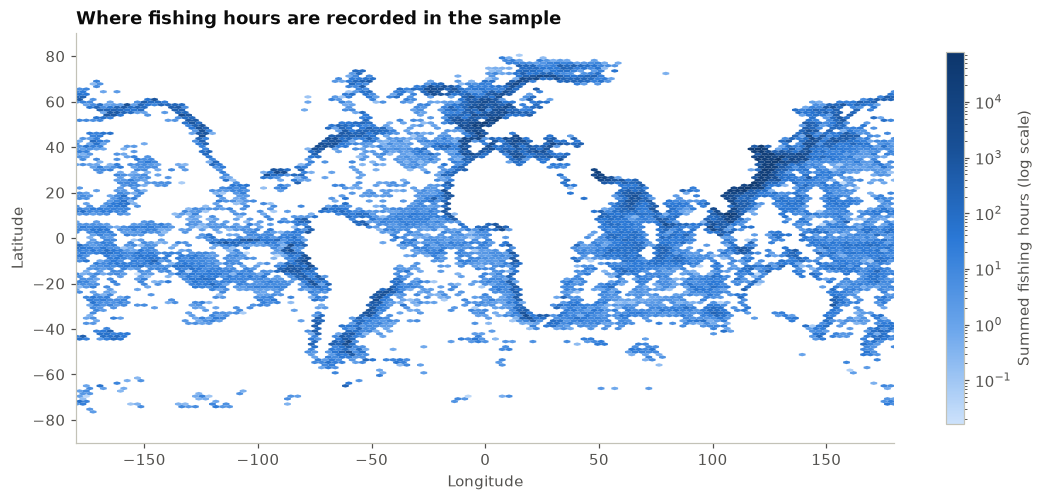

In [16]:
fig, ax = plt.subplots(figsize=(12, 5.5))
hb = ax.hexbin(df["cell_ll_lon"], df["cell_ll_lat"], C=df["fishing_hours"], reduce_C_function=np.sum,
               gridsize=120, cmap=SEQ, mincnt=1, linewidths=0, norm=mpl.colors.LogNorm())
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Where fishing hours are recorded in the sample")
fig.colorbar(hb, ax=ax, label="Summed fishing hours (log scale)", shrink=0.8)
save(fig, "06_fishing_map")

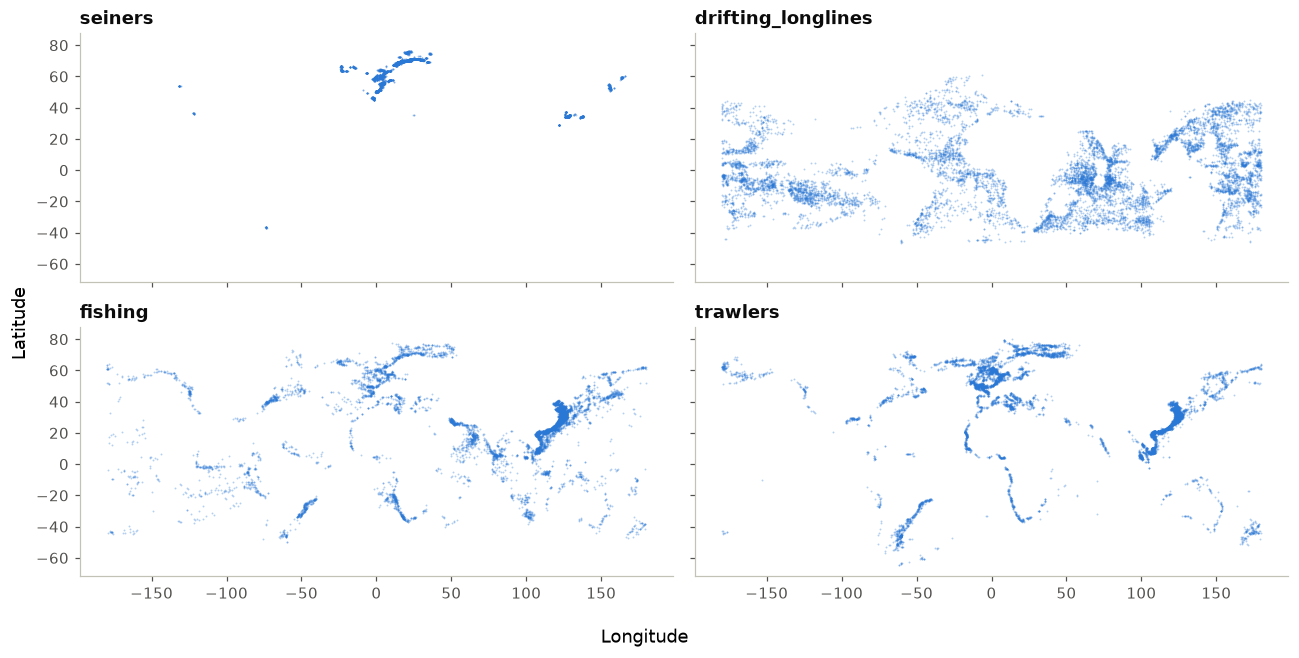

In [17]:
# Dominant gear types by latitude: how spatially clustered are they?
top = df["geartype"].value_counts().index[:4]
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for a, gname in zip(ax.ravel(), top):
    s = df[(df.geartype == gname) & (df.any_fishing == 1)]
    a.scatter(s["cell_ll_lon"], s["cell_ll_lat"], s=1.5, color=BLUE, alpha=0.35, linewidths=0)
    a.set_title(gname); a.grid(False)
fig.supxlabel("Longitude"); fig.supylabel("Latitude")
fig.tight_layout(); save(fig, "07_gear_maps")

## 9. Flag states
`UNKNOWN` and `UNKNOWN-CHN` appear because flags are partly inferred from the first three digits of the vessel identifier (MID), which can be wrong. They will be kept as their own category rather than dropped.

In [18]:
fl = (df.groupby("flag").agg(rows=("any_fishing", "size"), share_fishing=("any_fishing", "mean"),
                              mean_log_hours=("log_fishing_hours", "mean"))
        .sort_values("rows", ascending=False))
print(f"{len(fl)} flags; top 15 hold {fl['rows'].head(15).sum()/len(df):.1%} of rows")
fl.head(15).round(3)

274 flags; top 15 hold 74.1% of rows


,rows,share_fishing,mean_log_hours
flag,,,
CHN,45204,0.362,0.859
NOR,30223,0.226,0.327
USA,21078,0.185,0.288
JPN,20935,0.272,0.454
RUS,19170,0.165,0.250
GBR,18259,0.373,0.620
KOR,13360,0.457,1.084
TWN,11903,0.361,0.646
ESP,10004,0.336,0.536


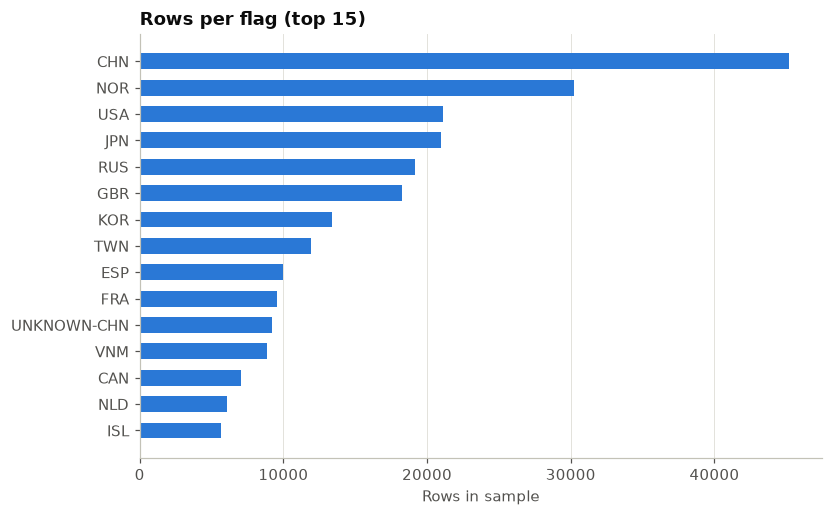

In [19]:
top15 = fl.head(15).sort_values("rows")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top15.index, top15["rows"], color=BLUE, height=0.6)
ax.set_title("Rows per flag (top 15)"); ax.set_xlabel("Rows in sample"); ax.grid(axis="y", visible=False)
save(fig, "08_top_flags")

## 10. Vessel features (flag × gear summary)

Missing vessel summaries: 1220 rows


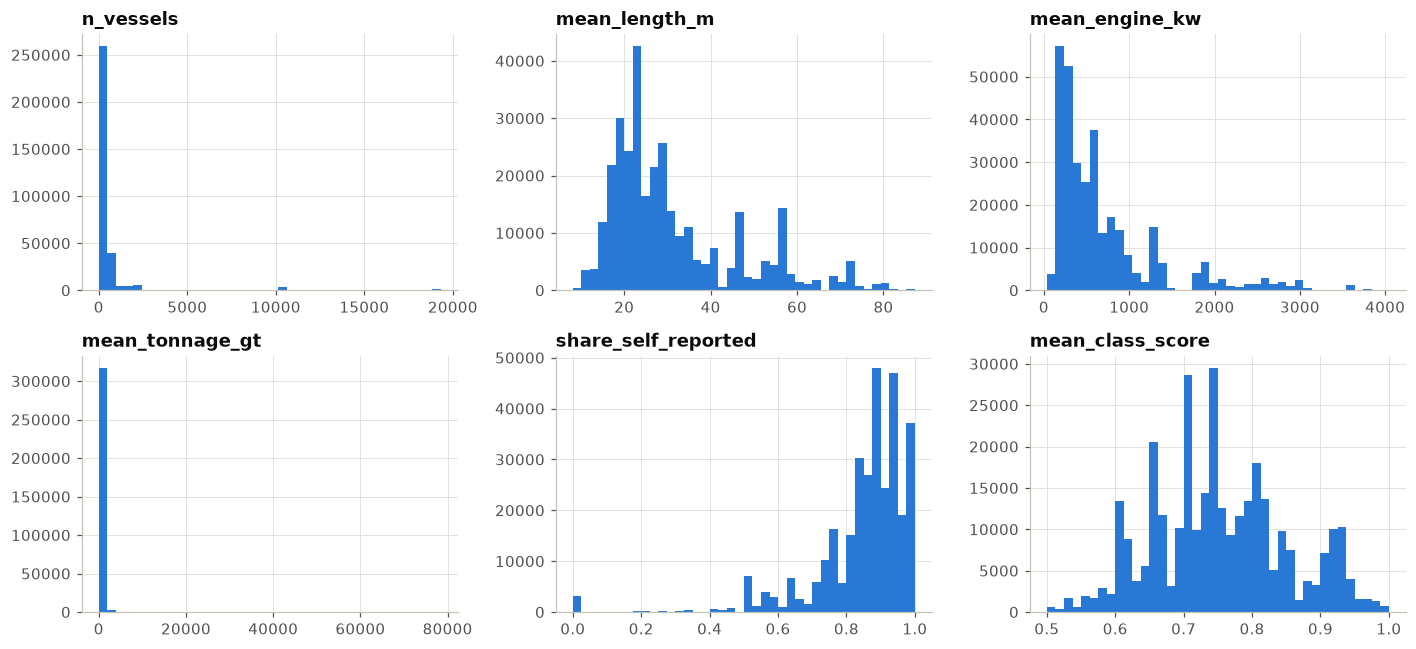

In [20]:
vf = ["n_vessels", "mean_length_m", "mean_engine_kw", "mean_tonnage_gt", "share_self_reported", "mean_class_score"]
print("Missing vessel summaries:", df[vf].isna().any(axis=1).sum(), "rows")
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, c in zip(ax.ravel(), vf):
    a.hist(df[c].dropna(), bins=40, color=BLUE); a.set_title(c)
fig.tight_layout(); save(fig, "09_vessel_feature_distributions")

## 11. Correlations and leakage
`hours` (total apparent activity) **includes** `fishing_hours`, so it is near-leakage for the target. We keep the Spearman matrix to document this and plan an experiment with and without `hours`.

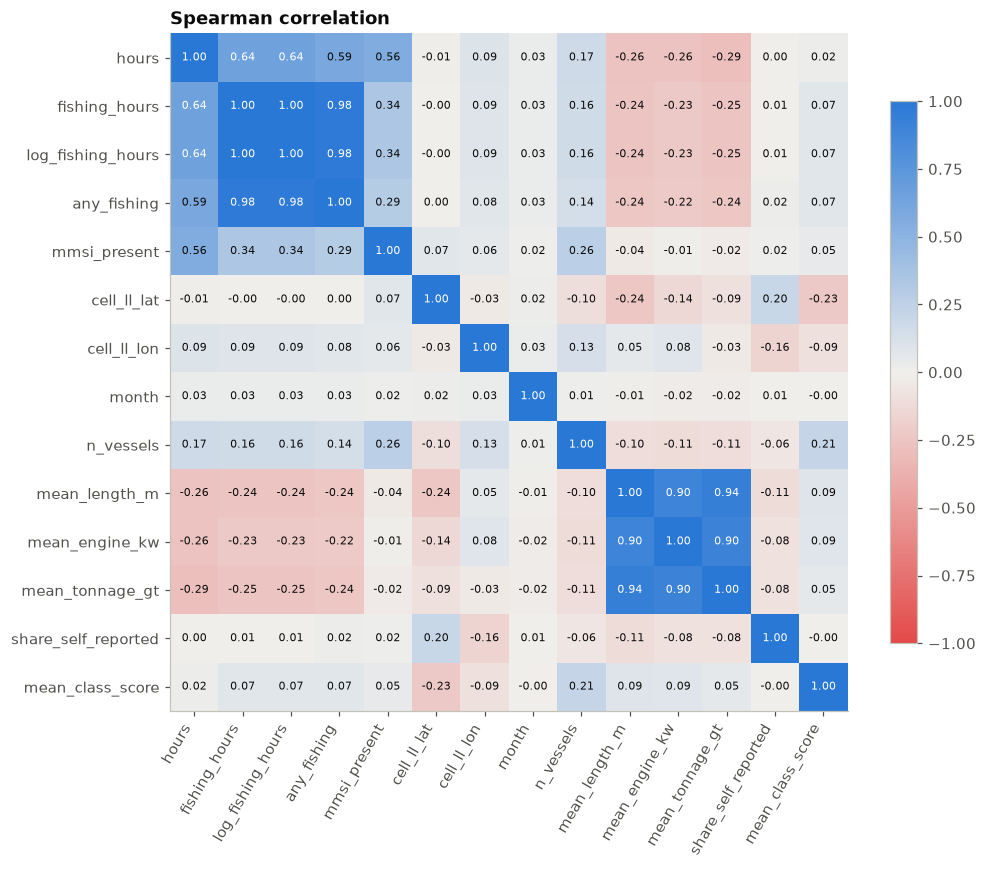

In [21]:
corr_cols = ["hours", "fishing_hours", "log_fishing_hours", "any_fishing", "mmsi_present", "cell_ll_lat",
             "cell_ll_lon", "month"] + vf
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else INK)
ax.set_title("Spearman correlation"); fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "10_correlation")

In [22]:
corr["log_fishing_hours"].drop(["fishing_hours", "log_fishing_hours", "any_fishing"]).sort_values(
    key=abs, ascending=False).round(3).to_frame("spearman with log_fishing_hours")

,spearman with log_fishing_hours
hours,0.642
mmsi_present,0.336
mean_tonnage_gt,-0.250
mean_length_m,-0.244
mean_engine_kw,-0.229
n_vessels,0.158
cell_ll_lon,0.089
mean_class_score,0.071
month,0.031
share_self_reported,0.008


In [23]:
# Pairs of features that are almost duplicates (|rho| > 0.8): candidates for removal
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
             .rename("rho").reset_index().query("abs(rho) > 0.8")
             .sort_values("rho", key=abs, ascending=False))
pairs.columns = ["feature_a", "feature_b", "rho"]
pairs.round(3)

,feature_a,feature_b,rho
16,fishing_hours,log_fishing_hours,1.000
17,fishing_hours,any_fishing,0.976
31,log_fishing_hours,any_fishing,0.976
137,mean_length_m,mean_tonnage_gt,0.937
151,mean_engine_kw,mean_tonnage_gt,0.904
136,mean_length_m,mean_engine_kw,0.896


## 12. Outliers

In [24]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

out = pd.Series({c: iqr_outliers(df[c].dropna()) for c in ["hours", "fishing_hours", "mean_length_m", "mean_engine_kw", "mean_tonnage_gt"]})
(out / len(df) * 100).round(1).to_frame("% IQR outliers")

,% IQR outliers
hours,15.9
fishing_hours,19.2
mean_length_m,5.2
mean_engine_kw,10.0
mean_tonnage_gt,12.3


In [25]:
# Positive-hours rows: how extreme is the top tail? (physical limit per cell-month is bounded by vessels present)
print(df[["hours", "fishing_hours"]].quantile([.9, .99, .999, 1]).round(1))

          hours  fishing_hours
0.900      25.5            9.9
0.990     474.3          123.8
0.999    2567.3          596.2
1.000  188783.4        12479.9


## 13. Findings and preprocessing decisions
*Fill the numbers in from the outputs above before writing the report; keep this cell as your evidence log.*

| Finding | Evidence (cell/figure) | Decision for notebook 02 |
|---|---|---|
| `fishing_hours` is zero-inflated | Section 5 | Two-part model: classifier for `any_fishing`, regressor on `log1p(fishing_hours)` for rows with fishing |
| Heavy right skew | Skewness, Fig 01 | `log1p` transform for `hours`, `fishing_hours` and other skewed features |
| `hours` contains fishing time | Section 11 | Report models with and without `hours`; treat with-`hours` as an upper bound |
| `UNKNOWN` flags | Section 3 and 9 | Keep as own category; test sensitivity by dropping them |
| Stratified sample distorts gear prevalence | Section 6 | Do not report prevalence from the sample; use macro-F1 for gear classification |
| Location and seasonality matter | Figs 04-07 | Add sin/cos month, keep lat/lon; **geographic block split** to avoid spatial leakage |
| Vessel features are flag × gear summaries | Section 10 | Treat as group-level context; fit imputers/scalers on the training split only |
| Redundant features | Section 11 pairs table | Drop or combine features with |rho| > 0.8 |